# Topic 5 - Machine Learning (Part 1)

---
**Note: Content extracted from CM3005 course materials (available via Coursera)**

---

---

**Topic Learning Objectives**:
1. Understand machine learning fundamentals
2. Use scikit-learn (sklearn) to apply machine learning techniques
3. Understand feature engineering and model validation

---

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 5.0 Introduction </h2>
</div>

### What is Machine Learning?
- A subfield of artificial intelligence (AI)?
- Building models from data
    * Parameters 'learnt' from samples
    * Predict, explore, understand

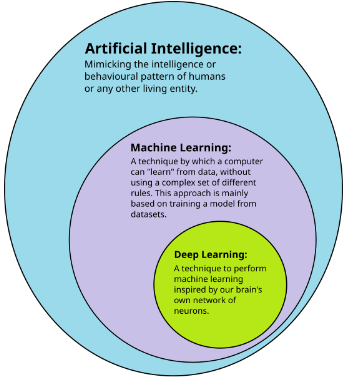

###### Source: Wikipedia. https://commons.wikimedia.org/wiki/File:AI-ML-DL.svg

### Machine Learning Approaches
- **Supervised learning** - From data to labels
    * Classification
    * Regression
- **Unsupervised learning** - Finding patterns in data
    * Clustering
    * Dimensionality reduction

### Machine Learning Example (1): Classification
- Goal: predict **discrete** labels
- Find a line that **separates** the **classes**
    * Learn the parameters of the line
- Generalize to:
    * New, unlabelled data
    * Higher dimensions
 
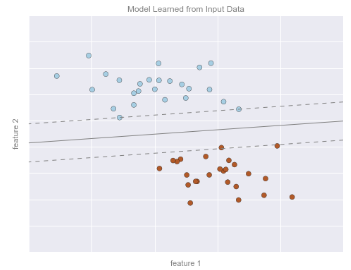

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.01-what-is-machine-learning.html

### Machine Learning Example (2): Regression
- Goal: predict **continuous** labels
- Model the **relationship** between **variables**
    * Learn the parameters from examples
- Generalize to:
    * New, unlabelled data
    * Higher dimensions
 
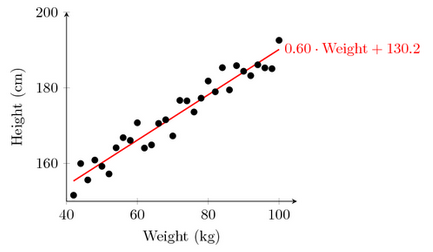

###### Source: PGFplots. https://pgfplots.net/regression-line/

### Machine Learning Example (3): Clustering
- Goal: infer **labels** on **unlabeled** data
- Use intrinsic **structure** to find **groups**
    * Determine which points are related
- Generalize to higher dimensions
    * kMeans algorithm

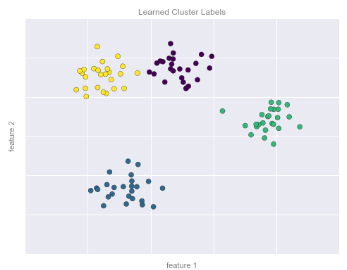

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.01-what-is-machine-learning.html

### Machine Learning Example (4): Dimensionality Reduction
- Goal: infer **structure** of **unlabeled** data
- Transform data from high-dimensional space to low-dimensional space
    * Preserve **meaningful properties** of the data
- Useful for complex data sets
    * 1,000s of features
    * Visualize using 2 or 3 dimensions

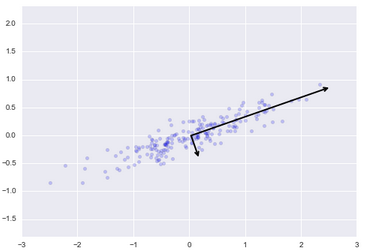

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.09-principal-component-analysis.html


<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 5.1 Introducing scikit-learn </h2>
</div>

### What is scikit-learn (sklearn)?
- Efficient versions of common machine learning algorithms
- Uniform API + documentation
- Easy to switch algorithms/models

### Data Representation in scikit-learn
- Data as tables: **two-dimensional** grid
    * Rows are **instances** (samples)
    * Columns are **attributes** (features)


- Example: Iris dataset
    ###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.02-introducing-scikit-learn.html

    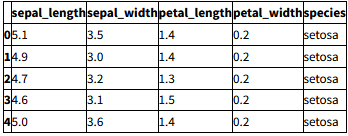

    - Predict target (i.e., species) based on measurements
    - Features matrix: X
        * 2 dimensional: **n_samples** * **n_features**
    - Target array: y
        * One dimensional: **n_samples**


### Supervised Learning: Overall Process
- Choose a **class** of model
- Set model **hyperparameters**
- **Configure** your data (X and y)
- **Fit** the model to your data
- **Apply** model to new (unseen) data

### Supervised Learning: Linear Regression

Goal: Fit a line to some 2D data

To start:
- Create some 'artificial' data for y = mx + c
- Slope = ~2
- Intercept = -1

Steps to follow:
1. Choose a class of model
    - Represented by a Python class, e.g., LinearRegression
2. Set model hyperparameters
    - Instantiate and configure your model
3. Configure your data (x and y)
    - Arrange into feature matrix and target vector
4. Fit the model to your data
    - Calculate the slope and intercept
5. Apply model to new data (predict labels for unseen data)
    - Create a grid of x values
    - Visualize the results
    - Plot raw data + model
  
... And evaluate


In [ ]:
# Sets environment variable to only use one CPU thread
# Helps prevents MKL-related memory leaks on Windows (common with KMeans)
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [ ]:
# Set up the data
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.RandomState(42)
x = 10 * rng.rand(50)
y = 2 * x - 1 + rng.randn(50)
plt.scatter(x, y);

In [ ]:
# Create a model
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)

In [ ]:
# Create the features matrix
X = x[:, np.newaxis]
X.shape

In [ ]:
model.fit(X, y)

In [ ]:
### Insert code to extract coefficient and intercept of the linear regression model
### Note: For y = mx + c,  m is the coefficient and c is the intercept


In [ ]:
# Create some new unseen data
xfit = np.linspace(-1, 11)  # default number of points is 50, shape is (50,)

# Arrange into a features matrix
Xfit = xfit[:, np.newaxis]  # inserts a new axis into array, shape is now (50, 1)

In [ ]:
# Predict target array
yfit = model.predict(Xfit)

In [ ]:
# Visualize the raw data and the model fit
plt.scatter(x, y)
plt.plot(xfit, yfit);

### Supervised Learning: Classification

Goal: classify samples based on measurements
- Using simple classifier: Naive Bayes
- Fast, minimal configuration

Need to evaluate model on unseen data
- Configure the data (x and y)
- Fit the model
- Predict on test set

Evaluate in terms of accuracy


In [ ]:
# Download the Iris dataset
import seaborn as sns
iris = sns.load_dataset('iris')

In [ ]:
### Insert code to explore what's contained in the Iris dataset


In [ ]:
# Extract the features matrix
X_iris = iris.drop('species', axis=1)
X_iris.shape

In [ ]:
# Extract the target array
y_iris = iris['species']
y_iris.shape

In [ ]:
# Split the data into a training set and test set
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(X_iris, y_iris, random_state=1)

In [ ]:
# Create and train a model
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(Xtrain, ytrain)
preds = model.predict(Xtest)

In [ ]:
# Evaluate the model
from sklearn.metrics import accuracy_score
accuracy_score(ytest, preds)

In [ ]:
# Additional - Evaluate the model (other metrics)
# Note: Iris dataset is a multi-class classification problem with 3 classes

# References:
# 1. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html#
# 2. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html

from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# Full classification report (includes precision, recall, F1 for each class)
report = classification_report(ytest, preds)
print(report)

# Micro average: Calculate metrics globally by counting the total true positives, false negatives and false positives
precision_micro = precision_score(ytest, preds, average='micro')  
recall_micro = recall_score(ytest, preds, average='micro')
f1_micro = f1_score(ytest, preds, average='micro')

# Macro average: Calculate metrics for each label, and find their unweighted mean
# Note: This does not take label imbalance into account.
precision_macro = precision_score(ytest, preds, average='macro')
recall_macro = recall_score(ytest, preds, average='macro')
f1_macro = f1_score(ytest, preds, average='macro')

# Weighted average: Calculate metrics for each label, and find their average weighted by support (the number of true instances for each label)
# Note: This alters ‘macro’ to account for label imbalance
precision_weighted = precision_score(ytest, preds, average='weighted')
recall_weighted = recall_score(ytest, preds, average='weighted')
f1_weighted = f1_score(ytest, preds, average='weighted')

# Print all metrics
print("micro avg: precision:", precision_micro, "recall:", recall_micro, "f1-score:", f1_micro)
print("macro avg: precision:", precision_macro, "recall:", recall_macro, "f1-score:", f1_macro)
print("weighted avg: precision:", precision_weighted, "recall:", recall_weighted, "f1-score:", f1_weighted)


### Unsupervised Learning: Dimensionality Reduction

Dimensionality reduction is a type of unsupervised learning

We use the iris dataset, which has 4 columns
- Can you visualize 4 dimensions?
- Try to reduce the number of dimensions, but retain essential features

Use principal components analysis (PCA):
- 4 dimensions -> 2 dimensions

Steps to follow:
- Choose a class of model
- Instantiate the model with hyperparameters
- Fit the model to your data
- Transform the data to 2 dimensions

Visualizing the results: Plot the results using Seaborn
- In 2D, the species are quite well separated
- PCA had no knowledge of labels!
- Classification should be possible

In [ ]:
# Download the iris dataset
import seaborn as sns
iris = sns.load_dataset('iris')
iris.head()

In [ ]:
# Extract the features matrix
X_iris = iris.drop('species', axis=1)
X_iris.shape

In [ ]:
from sklearn.decomposition import PCA   # 1. Choose the model class

In [ ]:
model = PCA(n_components=2)             # 2. Instantiate the model with hyperparameters

In [ ]:
model.fit(X_iris)                       # 3. Fit to data. Notice y is not specified!

In [ ]:
X_2D = model.transform(X_iris)          # 4. Transform the data to two dimensions

In [ ]:
iris['PCA1'] = X_2D[:, 0]
iris['PCA2'] = X_2D[:, 1]

In [ ]:
iris

In [ ]:
sns.lmplot(x='PCA1', y='PCA2', hue='species', data=iris, fit_reg=False);

### Unsupervised Learning: Clustering

Clustering is a type of unsupervised learning
- No labels!
- We are trying to find structure in data, e.g., meaningful groups
- Various techniques: kMeans, Gaussian Mixture Models

Steps to follow:
- Choose a class of model
- Set model hyperparameters
- Fit the model to your data
- Determine the clusters (and labels)

Visualizing the results:
- Add the cluster label (number) to the DataFrame
- Plot each cluster using Seaborn
    * -> Automatic species identification!?

In [ ]:
# Download the iris dataset
import seaborn as sns
iris = sns.load_dataset('iris')
iris.head()

In [ ]:
# Extract the features matrix
X_iris = iris.drop('species', axis=1)
X_iris.shape

In [ ]:
# Transform data from 4 to 2 dimensions using PCA
from sklearn.decomposition import PCA
model = PCA(n_components=2)
model.fit(X_iris)
X_2D = model.transform(X_iris)
iris['PCA1'] = X_2D[:, 0]
iris['PCA2'] = X_2D[:, 1]

In [ ]:
iris

In [ ]:
from sklearn.mixture import GaussianMixture                    # 1. Choose the model class

In [ ]:
model = GaussianMixture(n_components=3, 
                        covariance_type='full', n_init=1)      # 2. Instantiate model with hyperparameters

In [ ]:
model.fit(X_iris)                                              # 3. Fit to data. Notice y is not specified!

In [ ]:
y_gmm = model.predict(X_iris)                                  # 4. Determine cluster labels

In [ ]:
iris['cluster'] = y_gmm
iris

In [ ]:
sns.lmplot(x='PCA1', y='PCA2', data=iris, hue='species', col='cluster', fit_reg=False);

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> 5.2 Model Validation </h2>
</div>

---

**Review: A Simple Machine Learning Workflow**

1. Choose a **class** of model
2. Set model **hyperparameters**
3. **Configure** your data (x and y)
4. **Fit** the model to you data
5. **Apply** model to predict labels for new data

---

#### How do we know when our model is good enough?

- We need to **validate** our **choice of model** and **hyperparameters**


In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
X = iris.data
y = iris.target

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=1)

In [ ]:
model.fit(X, y)

In [ ]:
y_preds = model.predict(X)

In [ ]:
# Validate using our training data? That's like marking your own homework
from sklearn.metrics import accuracy_score
accuracy_score(y, y_preds)

### 5.2.1 Hold Out Sets

Validate using our training data? 
- That's like marking your own homework

Solution: use a **holdout set**
- Hold back some of the data for testing
- So that the model has not 'seen' it
- Better estimate of model's performance

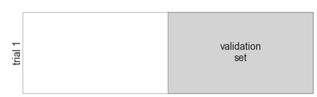

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html

But...
- We are 'wasting' part of our data (50%)
- A better solution: **cross-validataion**

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
X = iris.data
y = iris.target

In [ ]:
# Split the data into two halves
from sklearn.model_selection import train_test_split
X1, X2, y1, y2 = train_test_split(X, y, random_state=0, train_size=0.5)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=1)

In [ ]:
# Fit the model to the first half
model.fit(X1, y1)

In [ ]:
# Test it on the second half
y2_preds = model.predict(X2)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y2, y2_preds)

### 5.2.2 Cross Validation

How do we validate?
- Perform multiple splits
    * More trials
    * More folds = more robust estimates
    * Extreme example: leave-one-out
- Rotate the training and test portions
- Calculate the mean performance

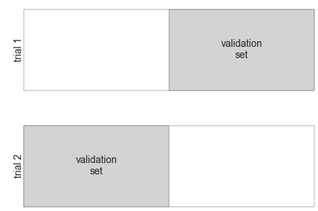

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html

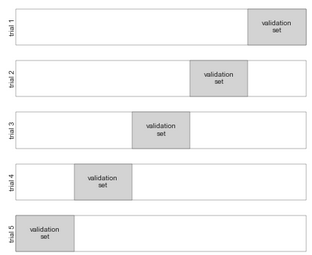

###### Source: Python Data Science Handbook. https://jakevdp.github.io/PythonDataScienceHandbook/05.03-hyperparameters-and-model-validation.html


In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

In [ ]:
X = iris.data
y = iris.target

In [ ]:
# Split the data into two halves
from sklearn.model_selection import train_test_split
X1, X2, y1, y2 = train_test_split(X, y, random_state=0, train_size=0.5)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=1)

In [ ]:
# Fit the model to each half and predict
y1_preds = model.fit(X2, y2).predict(X1)
y2_preds = model.fit(X1, y1).predict(X2)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y1, y1_preds), accuracy_score(y2, y2_preds)

In [ ]:
# Example - 2-fold cross validation (to get same results as before)
from sklearn.model_selection import cross_val_score, KFold
kf = KFold(n_splits=2, random_state=0, shuffle=True)  # control randomness in split
cross_val_score(model, X, y, cv=kf)

In [ ]:
# Example - 2-fold cross validation
from sklearn.model_selection import cross_val_score
cross_val_score(model, X, y, cv=2)

In [ ]:
# Example - 5-fold cross validation
from sklearn.model_selection import cross_val_score
cross_val_score(model, X, y, cv=5)

In [ ]:
# Example - leave-one-out cross validation
from sklearn.model_selection import LeaveOneOut
scores = cross_val_score(model, X, y, cv=LeaveOneOut())
scores

<div style="background:#e7f3fe; padding:10px; border-radius:5px;">
  <h2> References & Notes </h2>
</div>


**References**
- VanderPlas, J. (2016). *Python data science handbook: Essential tools for working with data*. O’Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/

**Notes**
- Excerpts from Python Data Science Handbook by Jake VanderPlas are used. The text is released under the CC-BY-NC-ND license, and the code examples are released under the MIT license.
- 'How deep learning is a subset of machine learning and how machine learning is a subset of artificial intelligence (AI)' by Avimanyu786. Creative Commons Attribution-Share Alike 4.0 International license.
- Some of the examples are from the PGFplots manual, which belongs to the PGFplotspackage which is released under GNU General Public License version 2.0 (GPLv2). All other examples are available under a Creative Commons attribution license.
license.